> 🔑 **SOLUTION EDITION.** This copy contains worked answers to every exercise. Try the student notebook first - you learn by struggling a little!

In [1]:
# (Solution edition only) make the course helper module importable from this folder
import sys; sys.path.insert(0, '../notebooks')

# 🌳 Lesson 2: Hierarchical Clustering
### *"Draw me the family tree of my crops."*

**Week 10 · Session 2 of 6 · ⏱ about 90 minutes**

---

### 🎯 Learning objectives
By the end of this lesson you will be able to:
1. Explain **agglomerative** clustering as "start with singletons, keep merging the closest pair".
2. Compare **single, complete, average, and Ward** linkage, and predict how each behaves.
3. **Read a dendrogram**: heights, branches, and where to cut.
4. Implement agglomerative clustering **from scratch** and verify against SciPy.
5. Use `scipy` and `scikit-learn` to cluster real data and **cut the tree** by number *or* by distance.
6. Decide when to choose hierarchical clustering over K-Means.

### 📋 Prerequisites
Lesson 1 (distance, scaling, profile). 

### 🔙 Where Lesson 1 left us
K-Means made you **commit to *k* in advance** and gave you a flat list of groups. But what if you want to **see the structure at every scale**: *"maize and sorghum are close cousins; both are cereals; cereals are closer to legumes than to livestock"*? That's a **hierarchy**, and it's what this lesson is about.

## 1 · The idea: build a family tree from the bottom up 🌱

**Story.** Imagine 48 agricultural commodities standing in a large hall, each wearing a badge with its price, shelf-life, volatility, and so on. You say:

1. *"Everyone is their own tiny group."*
2. *"The two **most similar** groups: shake hands and merge into one."*
3. *"Repeat. Always merge the two closest groups."*
4. *"Stop when there's one giant group."*

If you record **who merged with whom, and how far apart they were**, you've built a tree: the **dendrogram**. Cutting the tree at any level gives a clustering. Want 3 groups? Cut high. Want 10? Cut lower.

This bottom-up recipe is **agglomerative** clustering (the most common kind). *(The top-down opposite is called divisive; it's rarer.)*

| | **K-Means** | **Hierarchical (agglomerative)** |
|---|---|---|
| Must choose *k* first? | ✅ Yes | ❌ No: choose *after* seeing the tree |
| Output | One flat partition | A whole **tree** of partitions |
| Deterministic? | ❌ (depends on random start) | ✅ Yes, same data → same tree |
| Speed on big data | ✅ Very fast | ❌ Slow, memory-hungry ($n^2$) |
| Cluster shapes | Round blobs | Depends on **linkage** |

## 2 · A tiny example you can do with a pencil ✏️

Five villages lie along a highway at these kilometre marks:

| Village | A | B | C | D | E |
|---|---|---|---|---|---|
| km | 1 | 2 | 6 | 7 | 15 |

Distance between villages = the difference in km. Let's cluster them by hand using **single linkage** (distance between two groups = the distance between their **closest** members).

**Round 1.** Closest pair: A–B (distance 1) and C–D (distance 1). Merge them → groups {A,B}, {C,D}, {E}.

**Round 2.** Distances between groups (single linkage):
- {A,B} ↔ {C,D}: closest members are B(2) and C(6) → **4**
- {C,D} ↔ {E}: closest are D(7) and E(15) → **8**
- {A,B} ↔ {E}: closest are B(2) and E(15) → 13

Smallest is 4 → merge {A,B,C,D}.

**Round 3.** {A,B,C,D} ↔ {E}: closest are D(7) and E(15) → **8** → merge everything.

So the **merge heights** are: 1, 1, 4, 8. Let's confirm with SciPy, and draw the tree.

Each row of the linkage matrix Z:  [cluster_a, cluster_b, merge_height, size_of_new_cluster]

   cluster_a  cluster_b  height  new_size
0        0.0        1.0     1.0       2.0
1        2.0        3.0     1.0       2.0
2        5.0        6.0     4.0       4.0
3        4.0        7.0     8.0       5.0


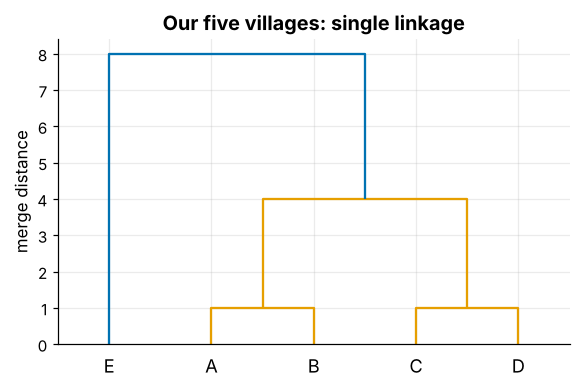

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.metrics import adjusted_rand_score
from course_utils import set_style, load, check, plot_clusters_2d
set_style()

km_marks = np.array([1, 2, 6, 7, 15]).reshape(-1, 1)   # each row = one village (1 feature)
Z_small = linkage(km_marks, method="single")
print("Each row of the linkage matrix Z:  [cluster_a, cluster_b, merge_height, size_of_new_cluster]\n")
print(pd.DataFrame(Z_small, columns=["cluster_a", "cluster_b", "height", "new_size"]).round(1))

plt.figure(figsize=(6, 3.6))
dendrogram(Z_small, labels=list("ABCDE"))
plt.ylabel("merge distance"); plt.title("Our five villages: single linkage"); plt.show()

**How to read the linkage matrix `Z`:** the original points are numbered 0–4 (A–E). Each merge creates a *new* cluster with the next free number (5, 6, 7, 8). So row 3 says "merge cluster 6 and cluster 4 (E) at height 8". 

**How to read the dendrogram:**
- Each **leaf** at the bottom is one data point.
- Each **U-shape** is a merge; the **height of the U** is the distance at which the merge happened.
- **Tall vertical lines** = a big jump in distance = "these groups really are different".
- Cut with a **horizontal line**: every vertical line it crosses is a cluster.

> 💡 **Intuition.** A dendrogram is a *zoom lens*. Zoomed out (cut high) you see the continents; zoomed in (cut low) you see the villages.

## 3 · The crucial choice: **linkage** 🔗

Once clusters have more than one member, "the distance between two clusters" is ambiguous. There are four classic definitions:

| Linkage | Distance between clusters $A$ and $B$ | Personality |
|---|---|---|
| **Single** | $\min_{a\in A,b\in B} d(a,b)$: the *closest* pair | Follows **chains**; finds elongated shapes; but suffers **"chaining"**: one stray point can bridge two groups |
| **Complete** | $\max_{a\in A,b\in B} d(a,b)$: the *farthest* pair | Makes **compact**, similar-diameter clusters; sensitive to outliers |
| **Average** | mean of all pairwise distances | A balanced compromise (a.k.a. UPGMA) |
| **Ward** | merge the pair that **increases total within-cluster variance the least** | Makes **round, equal-sized** clusters: behaves like hierarchical K-Means. Requires Euclidean distance. The usual default |

Let's compute all of them for our five villages, where we can still check by hand:

In [3]:
for method in ["single", "complete", "average", "ward"]:
    Z = linkage(km_marks, method=method)
    print(f"{method:9s} merge heights: {np.round(Z[:, 2], 2)}")

single    merge heights: [1. 1. 4. 8.]
complete  merge heights: [ 1.  1.  6. 14.]
average   merge heights: [ 1.  1.  5. 11.]
ward      merge heights: [ 1.    1.    7.07 13.91]


For `complete` linkage the 3rd merge is **6** (farthest members: A(1) and D(7)) rather than 4: complete linkage is *more reluctant* to join groups whose far ends are distant. Single linkage joined them at 4 because B and C are close.

## 4 · Build it from scratch 🔧

The algorithm is short enough to write in ~25 lines. It's deliberately *naive* (slow!) so that every step is visible.

In [4]:
def agglomerative_scratch(X, method="single"):
    """Naive agglomerative clustering. Returns the merge heights in order."""
    X = np.asarray(X, float)
    D = squareform(pdist(X))                        # all pairwise point distances
    clusters = {i: [i] for i in range(len(X))}      # cluster id -> list of member point indices
    next_id, merges = len(X), []

    def cluster_distance(a, b):
        block = D[np.ix_(clusters[a], clusters[b])]  # distances between every member of a and every member of b
        return {"single": block.min(), "complete": block.max(), "average": block.mean()}[method]

    while len(clusters) > 1:
        ids = list(clusters)
        best = (np.inf, None, None)
        for i in range(len(ids)):                    # look at EVERY pair of clusters...
            for j in range(i + 1, len(ids)):
                d = cluster_distance(ids[i], ids[j])
                if d < best[0]:
                    best = (d, ids[i], ids[j])       # ...and remember the closest
        d, a, b = best
        clusters[next_id] = clusters.pop(a) + clusters.pop(b)   # merge
        merges.append((a, b, d, len(clusters[next_id])))
        next_id += 1
    return np.array(merges)

# Compare with SciPy on 60 random points
rng = np.random.default_rng(0)
pts = rng.normal(size=(60, 2))
for method in ["single", "complete", "average"]:
    ours = agglomerative_scratch(pts, method)[:, 2]
    theirs = linkage(pts, method)[:, 2]
    print(f"{method:9s}  heights identical to SciPy?  {np.allclose(np.sort(ours), np.sort(theirs))}")

single     heights identical to SciPy?  True


complete   heights identical to SciPy?  True


average    heights identical to SciPy?  True


> 🧠 **Remember.** Our scratch version checks **every pair of clusters at every step**: roughly $O(n^3)$ time. SciPy uses smarter algorithms ($O(n^2)$), but still must store all pairwise distances, so hierarchical clustering struggles beyond ~10–20 thousand points. For big data: K-Means, or sample first.

## 5 · Linkage in action: why it matters 🎨

Let's run all four linkages on three shapes: blobs, two moons, and two rings. **Predict** before you look: which linkage will handle the moons? The rings?

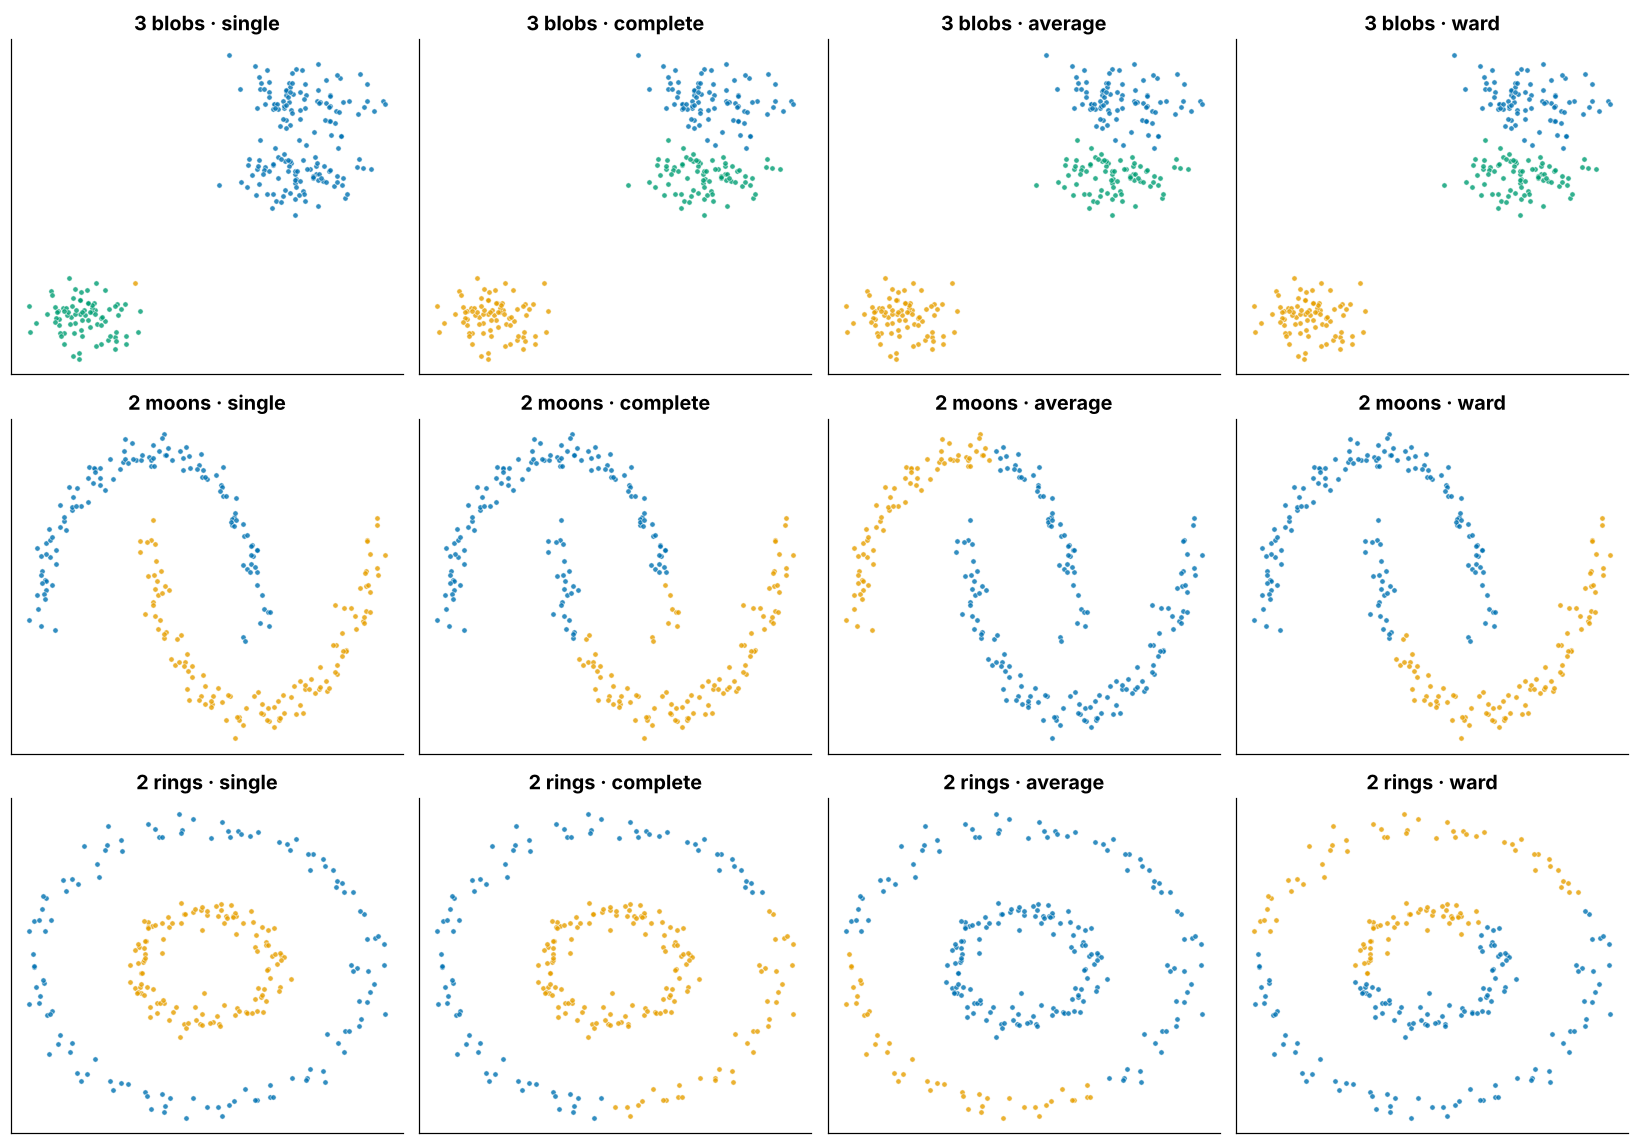

In [5]:
rng = np.random.default_rng(5)
datasets = {
    "3 blobs":   (make_blobs(250, centers=3, cluster_std=0.8, random_state=4)[0], 3),
    "2 moons":   (make_moons(250, noise=0.06, random_state=1)[0], 2),
    "2 rings":   (make_circles(250, factor=0.4, noise=0.05, random_state=1)[0], 2),
}
methods = ["single", "complete", "average", "ward"]

fig, axes = plt.subplots(3, 4, figsize=(15, 10.5))
for r, (name, (data, k)) in enumerate(datasets.items()):
    for c, method in enumerate(methods):
        lab = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(data)
        plot_clusters_2d(data, lab, ax=axes[r, c], s=12, title=f"{name} · {method}")
        axes[r, c].legend().set_visible(False); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
plt.tight_layout(); plt.show()

**What you should see:**
- **Single** linkage nails the moons and the rings (it can follow thin chains). But look at the top-left panel: on the blobs it **merges two neighbouring blobs** through a few bridging points: that's **chaining**, single linkage's signature weakness.
- **Ward** and **average** handle the blobs well but cut the moons and rings with straight-ish boundaries, much like K-Means would.
- **Complete** surprises us on the rings (it happens to separate them) but fails on the moons. Don't over-generalise from one picture: *always test on your own data.*

> ⚠️ **Watch out.** No linkage is "best". **Match the linkage to the shape you expect.** For typical business data (roughly blob-like, with noise), **Ward** is the best first try. For long, thin structures, try single: *but check for chaining*.

## 6 · Worked example 🌾: A family tree of agricultural products

**Business question.** A marketing board wants to group **48 commodities** by *market behaviour* (price level, volatility, seasonality, shelf life, elasticity, wholesale share, export share, margin, volume, number of markets) to design storage and price-support policies. Who behaves alike?

48 items is a perfect size for a hierarchy: small enough to read every leaf label.

In [6]:
products = load("products")
products.head(8)

,product,avg_price_kes_per_kg,price_cv,seasonality_amplitude,shelf_life_days,demand_elasticity,wholesale_share,export_share,avg_margin_pct,monthly_volume_tonnes,markets_traded_in
0,Maize,44.8,0.101,0.187,483,0.37,0.58,0.04,15.4,12241,65
1,Wheat,54.6,0.102,0.143,332,0.20,0.40,0.03,15.9,20682,68
2,Rice,45.9,0.090,0.098,270,0.69,0.53,0.00,12.0,18389,54
3,Sorghum,41.2,0.095,0.160,190,0.17,0.52,0.05,14.3,111742,74
4,Millet,23.8,0.136,0.233,389,0.10,0.51,0.01,13.8,63572,67
5,Barley,34.5,0.144,0.180,509,0.34,0.57,0.03,10.8,83657,70
6,Beans,167.8,0.110,0.172,298,0.71,0.28,0.07,12.2,1441,49
7,Green Grams,104.2,0.182,0.282,362,0.37,0.38,0.03,19.5,4855,50


**Preparation recipe** (same as Lesson 1):
1. Features = every numeric column.
2. **Log-transform** the columns spanning orders of magnitude (price, volume, shelf life). Otherwise a few huge values squash everything else.
3. **Standardise**.

In [7]:
prod_features = [c for c in products.columns if c != "product"]
Xp = products[prod_features].copy()
for col in ["avg_price_kes_per_kg", "monthly_volume_tonnes", "shelf_life_days"]:
    Xp[col] = np.log10(Xp[col])                      # orders of magnitude -> comparable steps
Xp_scaled = StandardScaler().fit_transform(Xp)
print("Prepared matrix:", Xp_scaled.shape, "(48 products x 10 features)")

Prepared matrix: (48, 10) (48 products x 10 features)


### Which linkage fits the data best? The cophenetic correlation

A dendrogram *distorts* the true distances (it can only record the height at which two points merged). The **cophenetic correlation** measures how faithfully the tree preserves the original pairwise distances: closer to **1 = more faithful**. 

In [8]:
orig_dists = pdist(Xp_scaled)
for method in ["single", "complete", "average", "ward"]:
    c, _ = cophenet(linkage(Xp_scaled, method), orig_dists)
    print(f"{method:9s} cophenetic correlation = {c:.3f}")

single    cophenetic correlation = 0.632
complete  cophenetic correlation = 0.717
average   cophenetic correlation = 0.741
ward      cophenetic correlation = 0.693


Average linkage preserves distances best, but Ward gives the most *interpretable, balanced* clusters (it optimises compactness). Cophenetic correlation is a fidelity measure, not a verdict: we'll use **Ward** for the tree and keep average as a cross-check.

### Draw the tree 🌳

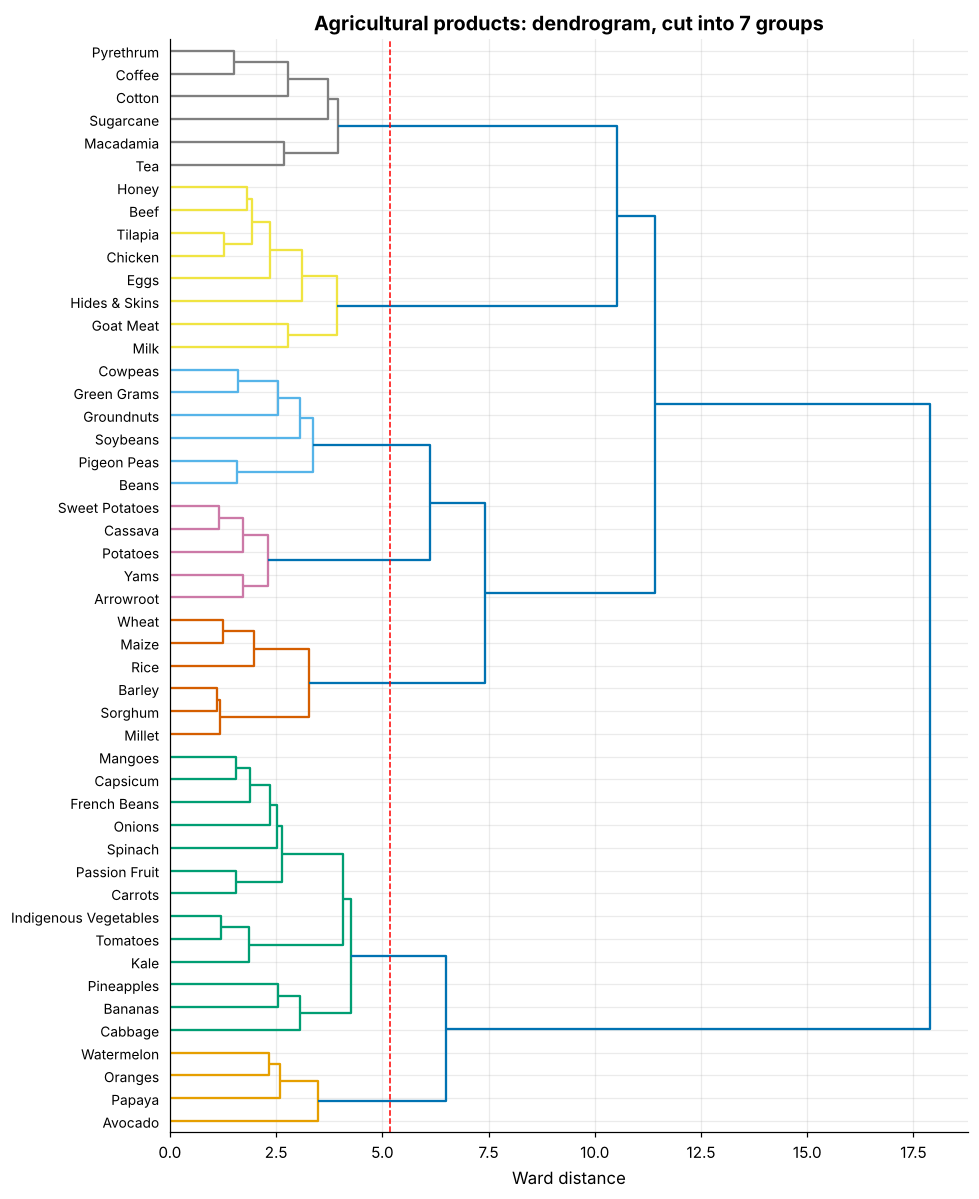

In [9]:
Z = linkage(Xp_scaled, method="ward")

K = 7
cut_height = (Z[-K, 2] + Z[-K + 1, 2]) / 2            # a height that yields exactly K clusters

plt.figure(figsize=(9, 11))
dendrogram(Z, labels=products["product"].values, orientation="right", color_threshold=cut_height, leaf_font_size=9)
plt.axvline(cut_height, color="red", ls="--", lw=1)
plt.xlabel("Ward distance"); plt.title(f"Agricultural products: dendrogram, cut into {K} groups")
plt.tight_layout(); plt.show()

**Reading this tree.** The final merges (far right, big jumps) separate really different families; the early merges (left) join near-twins. Notice there are really **two natural zoom levels**: the biggest jumps are near the top (cut at ~4 clusters: *plants-for-eating vs. cash crops/livestock* and so on), but a cut at **7** (red line) gives finer groups that are still clean and each easy to name: cereals, legumes, roots & tubers, cash crops, livestock products, and two perishable-produce branches. We choose 7 because it's *actionable*; a tree lets you justify either choice. (Remember Lesson 1: the metrics are evidence, not a command.)

### Cut the tree and look at the groups

In [10]:
products["group"] = fcluster(Z, t=K, criterion="maxclust")      # labels 1..K
for g, members in products.groupby("group")["product"]:
    print(f"Group {g} ({len(members):2d}): " + ", ".join(members))

Group 1 ( 4): Avocado, Oranges, Watermelon, Papaya
Group 2 (13): Tomatoes, Kale, Cabbage, Onions, Spinach, Capsicum, Carrots, French Beans, Indigenous Vegetables, Bananas, Mangoes, Pineapples, Passion Fruit
Group 3 ( 6): Maize, Wheat, Rice, Sorghum, Millet, Barley
Group 4 ( 5): Potatoes, Cassava, Sweet Potatoes, Arrowroot, Yams
Group 5 ( 6): Beans, Green Grams, Cowpeas, Pigeon Peas, Groundnuts, Soybeans
Group 6 ( 8): Milk, Eggs, Beef, Goat Meat, Chicken, Honey, Tilapia, Hides & Skins
Group 7 ( 6): Tea, Coffee, Cotton, Sugarcane, Pyrethrum, Macadamia


### Heatmap: *why* do the groups form?
A **clustermap** shows each product's standardised features as coloured cells, with products ordered by the tree. Red = high, blue = low. Look for columns that light up for particular groups.

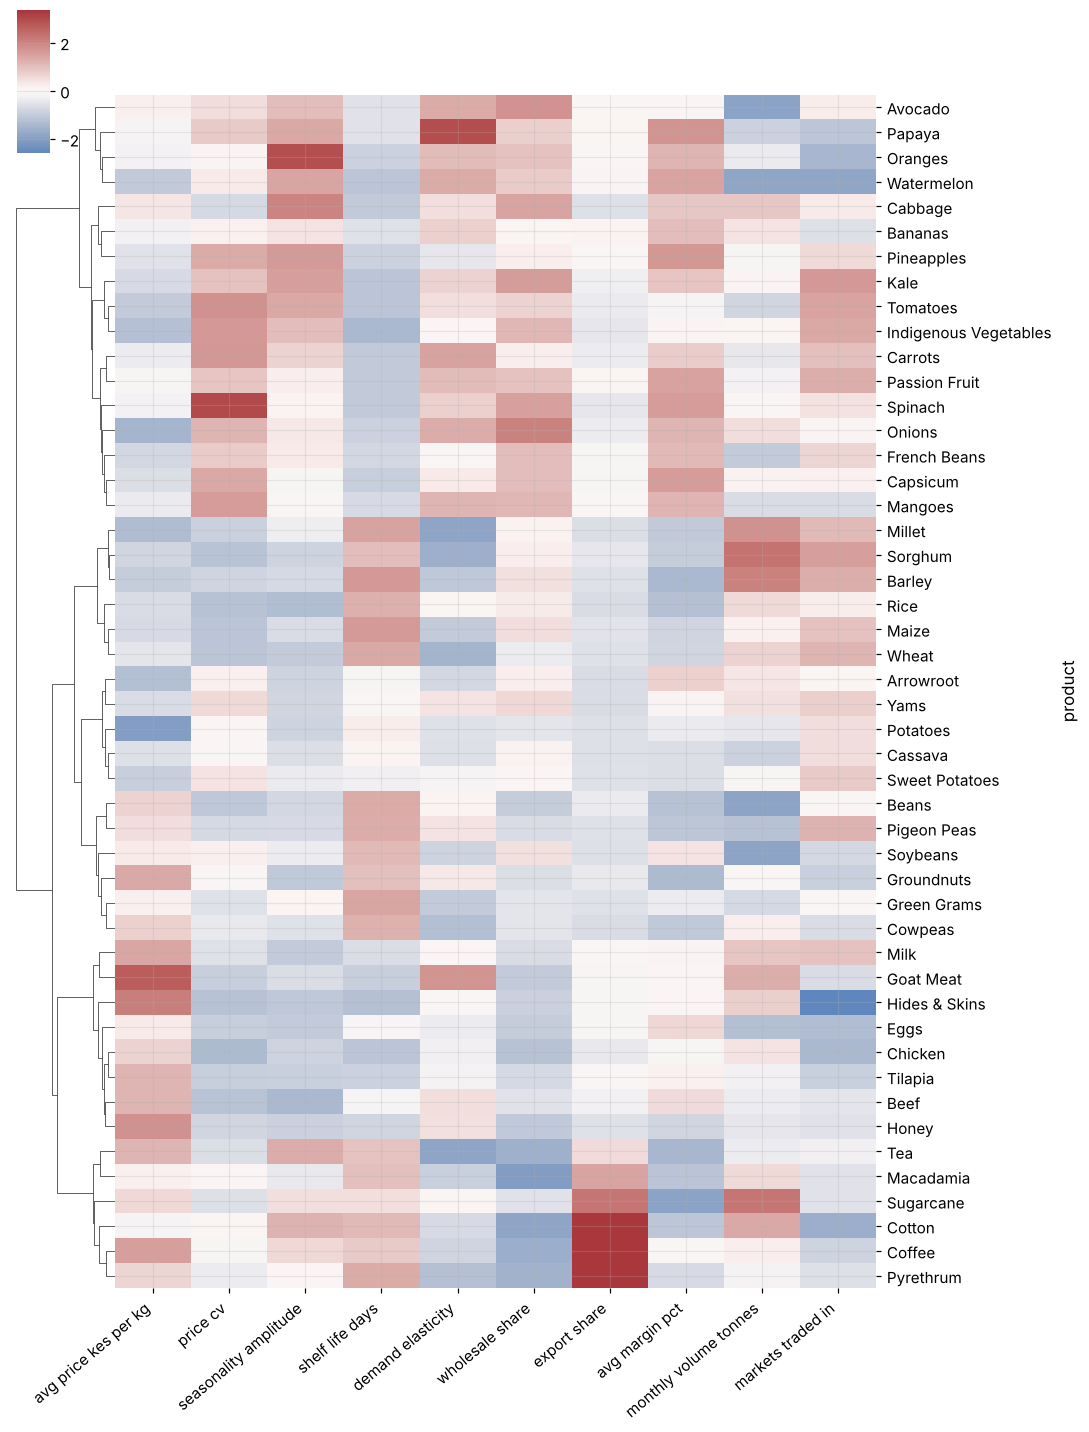

In [11]:
import seaborn as sns
feat_df = pd.DataFrame(Xp_scaled, columns=[c.replace("_", " ") for c in prod_features], index=products["product"])
g = sns.clustermap(feat_df, row_linkage=Z, col_cluster=False, cmap="vlag", center=0, figsize=(10, 13),
                   yticklabels=True, dendrogram_ratio=(0.12, 0.02), cbar_pos=(0.02, 0.93, 0.03, 0.1))
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), rotation=40, ha="right")
plt.show()

You can now *explain* the groups: e.g. one block is red on `price cv`, `seasonality amplitude`, and blue on `shelf life days`: **perishables with volatile prices**; another is red on `shelf life days` and `monthly volume tonnes` and blue on `price cv`: **storable staples**; another is red on `export share`: **cash crops**.

### 🔓 Reveal
Our synthetic products were generated from 7 commodity categories. How well does the tree rediscover them?

In [12]:
truth = load("products_truth")
print(f"ARI between the 7-group cut and the real categories: {adjusted_rand_score(truth['category'], products['group']):.2f}\n")
pd.crosstab(truth["category"], products["group"])

ARI between the 7-group cut and the real categories: 0.81



group,1,2,3,4,5,6,7
category,,,,,,,
Cash Crop,0,0,0,0,0,0,6
Cereal,0,0,6,0,0,0,0
Fruit,4,4,0,0,0,0,0
Legume,0,0,0,0,6,0,0
Livestock Product,0,0,0,0,0,8,0
Root & Tuber,0,0,0,5,0,0,0
Vegetable,0,9,0,0,0,0,0


Strong agreement, with some instructive mix-ups: **fruits and vegetables** (both perishable) tend to blend, and **legumes/roots** can overlap with cereals. Clusters group items by *market behaviour*, not by botanical category, which is often exactly what a policy-maker wants!

> 🌾 **Agricultural lens.** A tree like this is a ready-made policy map: *"Any intervention that works for tomatoes (cold-chain, price-information SMS) will likely work for kale and cabbage too, because they sit on the same branch."*

## 7 · Cutting by **distance** instead of number

Sometimes it's more natural to say *"treat anything closer than distance $t$ as the same group"* than to fix $k$. Two ways in code:

In [13]:
# SciPy: criterion="distance" cuts at a height; criterion="maxclust" asks for k groups
labels_by_height = fcluster(Z, t=cut_height, criterion="distance")
print("Clusters when cutting at height", round(cut_height, 1), ":", len(set(labels_by_height)))

# scikit-learn: n_clusters=None + distance_threshold
agg = AgglomerativeClustering(n_clusters=None, distance_threshold=cut_height, linkage="ward").fit(Xp_scaled)
print("scikit-learn agrees:", agg.n_clusters_, "clusters;  identical labelling to SciPy:",
      adjusted_rand_score(labels_by_height, agg.labels_) == 1.0)

Clusters when cutting at height 5.2 : 7
scikit-learn agrees: 7 clusters;  identical labelling to SciPy: True


## 8 · Hierarchical vs K-Means: which should I use?

| Situation | Pick |
|---|---|
| < ~5,000 rows, want to **explore** and see the structure | **Hierarchical** |
| Don't know *k* and want evidence from a visual | **Hierarchical** |
| Naturally hierarchical domain (taxonomies, product families, org charts) | **Hierarchical** |
| Large data (10,000+ rows) | **K-Means** |
| Need to assign **new** data points later | **K-Means** (`.predict`) |
| Want a quick, stable partition for operations | **K-Means** |

A common professional pattern: **use a dendrogram on a sample to pick *k*, then run K-Means on the full dataset.**

> ⚠️ **Watch out.** Hierarchical merges are **greedy and irreversible**: once two points are merged, they're never separated, even if a later merge would have made that a mistake. And scikit-learn's `AgglomerativeClustering` has no `.predict()` for new points.

## 9 · 🧩 Your turn: practice problems

### 🧩 Exercise 1: The distance matrix
**Difficulty:** ⭐  |  **Time:** ~7 min

Six villages along a highway are at these km marks:

```python
villages_km = np.array([0, 3, 10, 12, 30, 31])
```

1. Build the full 6×6 distance matrix `D` (hint: `squareform(pdist(...))`; `pdist` needs a 2-D array).
2. Find the **closest pair** of villages: store the indices as a tuple `closest_pair = (i, j)` with `i < j`.

<details><summary>💡 Hint 1</summary>

`pdist` expects shape (n, n_features): reshape with `villages_km.reshape(-1, 1)`.

</details>
<details><summary>💡 Hint 2</summary>

The diagonal of `D` is all zeros (every village is 0 away from itself). Copy `D` and fill the diagonal with `np.inf` so the minimum can't be a village paired with itself.

</details>
<details><summary>💡 Hint 3</summary>

`np.unravel_index(np.argmin(D2), D2.shape)` converts the flat argmin position into a (row, col) pair. Use `sorted(...)` to get i < j.

</details>

In [14]:
villages_km = np.array([0, 3, 10, 12, 30, 31])
D = squareform(pdist(villages_km.reshape(-1, 1)))
D2 = D.copy(); np.fill_diagonal(D2, np.inf)
i, j = sorted(np.unravel_index(np.argmin(D2), D2.shape))
closest_pair = (int(i), int(j))
print(D.astype(int)); print("closest pair:", closest_pair)

[[ 0  3 10 12 30 31]
 [ 3  0  7  9 27 28]
 [10  7  0  2 20 21]
 [12  9  2  0 18 19]
 [30 27 20 18  0  1]
 [31 28 21 19  1  0]]
closest pair: (4, 5)


In [15]:
# ✔ Self-check (run me after you've written your answer)
check('D is 6x6', lambda: D.shape == (6, 6))
check('D is symmetric with zero diagonal', lambda: np.allclose(D, D.T) and np.allclose(np.diag(D), 0))
check('closest pair is villages 4 and 5 (30 km and 31 km)', lambda: closest_pair == (4, 5))

✅ D is 6x6
✅ D is symmetric with zero diagonal
✅ closest pair is villages 4 and 5 (30 km and 31 km)


### 🧩 Exercise 2: Linkage distance by hand
**Difficulty:** ⭐  |  **Time:** ~5 min

Two clusters of villages (km marks): `A = [0, 3]` and `B = [10, 12]`.

Compute the distance between A and B under each linkage and store in `d_single`, `d_complete`, `d_average`.
(Compute all four point-to-point distances first. You can do it with a list comprehension or `np.abs(np.subtract.outer(A, B))`.)

<details><summary>💡 Hint 1</summary>

`pair_d = np.abs(np.subtract.outer(A, B))` gives a 2×2 matrix of all |a − b| values.

</details>
<details><summary>💡 Hint 2</summary>

single = the **min** of that matrix, complete = the **max**, average = the **mean**.

</details>

In [16]:
A = np.array([0, 3]); B = np.array([10, 12])
pair_d = np.abs(np.subtract.outer(A, B))
d_single, d_complete, d_average = pair_d.min(), pair_d.max(), pair_d.mean()
print(pair_d, d_single, d_complete, d_average)

[[10 12]
 [ 7  9]] 7 12 9.5


In [17]:
# ✔ Self-check (run me after you've written your answer)
check('single linkage distance is 7 (3 → 10)', lambda: d_single == 7)
check('complete linkage distance is 12 (0 → 12)', lambda: d_complete == 12)
check('average linkage distance is 9.5', lambda: abs(d_average - 9.5) < 1e-9)

✅ single linkage distance is 7 (3 → 10)
✅ complete linkage distance is 12 (0 → 12)
✅ average linkage distance is 9.5


### 🧩 Exercise 3: Who are Tomatoes' closest relatives?
**Difficulty:** ⭐⭐  |  **Time:** ~8 min

Using `Xp_scaled` and `products` from the worked example:

1. Build a Ward linkage matrix `Z_w`.
2. Cut it into **7** clusters with `fcluster(..., criterion="maxclust")` → `lab7`.
3. Create `tomato_mates`: the **list of product names** in the same cluster as `"Tomatoes"` (including Tomatoes itself).

<details><summary>💡 Hint 1</summary>

`Z_w = linkage(Xp_scaled, method='ward')`, then `lab7 = fcluster(Z_w, t=7, criterion='maxclust')`.

</details>
<details><summary>💡 Hint 2</summary>

Find Tomatoes' row: `i = products.index[products['product'] == 'Tomatoes'][0]` and its cluster label is `lab7[i]`.

</details>
<details><summary>💡 Hint 3</summary>

`products['product'][lab7 == lab7[i]].tolist()` gives the names of everything in that cluster.

</details>

In [18]:
Z_w = linkage(Xp_scaled, method="ward")
lab7 = fcluster(Z_w, t=7, criterion="maxclust")
i = products.index[products["product"] == "Tomatoes"][0]
tomato_mates = products["product"][lab7 == lab7[i]].tolist()
print(tomato_mates)

['Tomatoes', 'Kale', 'Cabbage', 'Onions', 'Spinach', 'Capsicum', 'Carrots', 'French Beans', 'Indigenous Vegetables', 'Bananas', 'Mangoes', 'Pineapples', 'Passion Fruit']


In [19]:
# ✔ Self-check (run me after you've written your answer)
check('lab7 has 7 distinct clusters', lambda: len(set(lab7)) == 7)
check('Tomatoes is in its own list', lambda: 'Tomatoes' in tomato_mates)
check('Kale is a close relative (both fresh vegetables)', lambda: 'Kale' in tomato_mates)
check('Maize is NOT (a storable cereal)', lambda: 'Maize' not in tomato_mates)

✅ lab7 has 7 distinct clusters
✅ Tomatoes is in its own list
✅ Kale is a close relative (both fresh vegetables)
✅ Maize is NOT (a storable cereal)


### 🧩 Exercise 4: Pick the most faithful linkage
**Difficulty:** ⭐⭐  |  **Time:** ~8 min

Compute the **cophenetic correlation** for linkages `"single"`, `"complete"`, `"average"` and `"ward"` on `Xp_scaled`, storing results in a dict `coph` (`{"single": ..., ...}`). Then set `best_linkage` to the key with the highest value.

*After you've done it, think: does the "most faithful" linkage automatically give the "most useful" clusters? (Discuss with a friend!)*

<details><summary>💡 Hint 1</summary>

`cophenet(Z, pdist(X))` returns a pair `(correlation, cophenetic_distances)`. You need the first element.

</details>
<details><summary>💡 Hint 2</summary>

Loop over the four method names, building `Z = linkage(Xp_scaled, method=m)` each time.

</details>
<details><summary>💡 Hint 3</summary>

`best_linkage = max(coph, key=coph.get)`

</details>

In [20]:
coph = {}
for m in ["single", "complete", "average", "ward"]:
    coph[m] = cophenet(linkage(Xp_scaled, method=m), pdist(Xp_scaled))[0]
best_linkage = max(coph, key=coph.get)
print({k: round(v, 3) for k, v in coph.items()}, "->", best_linkage)

{'single': np.float64(0.632), 'complete': np.float64(0.717), 'average': np.float64(0.741), 'ward': np.float64(0.693)} -> average


In [21]:
# ✔ Self-check (run me after you've written your answer)
check('coph has all four linkages', lambda: set(coph) == {'single', 'complete', 'average', 'ward'})
check('all values are valid correlations', lambda: all(0 < v <= 1 for v in coph.values()))
check('best_linkage is the argmax', lambda: coph[best_linkage] == max(coph.values()))
check('average linkage wins on this dataset', lambda: best_linkage == 'average')

✅ coph has all four linkages
✅ all values are valid correlations
✅ best_linkage is the argmax
✅ average linkage wins on this dataset


### 🧩 Exercise 5: Markets: cutting a tree by height
**Difficulty:** ⭐⭐  |  **Time:** ~10 min

Cluster the **markets** with Ward linkage on these standardised features:

```python
market_cols = ["avg_daily_traders", "avg_daily_volume_tonnes", "price_volatility", "distance_to_city_km",
               "road_quality_1_5", "has_cold_storage", "perishable_share", "n_commodities",
               "mobile_payment_share", "market_days_per_week"]
```
Store the linkage in `Zm`. Then determine how many clusters you get when cutting the tree at height **10** (`n_at_10`) and at height **20** (`n_at_20`).

<details><summary>💡 Hint 1</summary>

`markets = load('markets')`; `Xm = StandardScaler().fit_transform(markets[market_cols])`; `Zm = linkage(Xm, 'ward')`.

</details>
<details><summary>💡 Hint 2</summary>

`fcluster(Zm, t=10, criterion='distance')` returns labels; the number of clusters is `len(set(labels))`.

</details>
<details><summary>💡 Hint 3</summary>

Look at `Zm[-6:, 2]`: the last six merge heights: to see *why* the counts change where they do.

</details>

In [22]:
market_cols = ["avg_daily_traders", "avg_daily_volume_tonnes", "price_volatility", "distance_to_city_km",
               "road_quality_1_5", "has_cold_storage", "perishable_share", "n_commodities",
               "mobile_payment_share", "market_days_per_week"]
markets = load("markets")
Xm = StandardScaler().fit_transform(markets[market_cols])
Zm = linkage(Xm, method="ward")
n_at_10 = len(set(fcluster(Zm, t=10, criterion="distance")))
n_at_20 = len(set(fcluster(Zm, t=20, criterion="distance")))
print(n_at_10, n_at_20, "| last merge heights:", Zm[-6:, 2].round(1))

4 2 | last merge heights: [ 5.1  5.1  9.  10.2 16.9 34.8]


In [23]:
# ✔ Self-check (run me after you've written your answer)
check('Zm has 102 merges (103 markets)', lambda: Zm.shape == (102, 4))
check('cutting at 10 gives 4 clusters', lambda: n_at_10 == 4)
check('cutting at 20 gives 2 clusters', lambda: n_at_20 == 2)

✅ Zm has 102 merges (103 markets)
✅ cutting at 10 gives 4 clusters
✅ cutting at 20 gives 2 clusters


### 🧩 Exercise 6: 🏆 Challenge: let the dendrogram suggest k
**Difficulty:** ⭐⭐⭐  |  **Time:** ~15 min

A popular heuristic: *"cut where there's the biggest **gap** between consecutive merge heights"* (a tall vertical line = very different groups being merged).

Write `suggest_k(Z)` that returns that suggested number of clusters.

**Details.** With `n` points, `Z` has `n-1` rows. If `h = Z[:, 2]` are the merge heights, then cutting between `h[i]` and `h[i+1]` leaves `n - (i + 1)` clusters. So: find `i = argmax(diff(h))` and return `n - (i + 1)`.

Test on the 4-blob data `X_blobs` below. Then try it on other datasets. **Is it reliable?** (Spoiler: not always: it tends to favour small *k*. Why?)

<details><summary>💡 Hint 1</summary>

`h = Z[:, 2]`, `gaps = np.diff(h)` (length n-2), `i = int(np.argmax(gaps))`.

</details>
<details><summary>💡 Hint 2</summary>

`n = Z.shape[0] + 1`  (rows = n − 1).

</details>
<details><summary>💡 Hint 3</summary>

Return `n - (i + 1)`. Check by hand on `Z_small` from Section 2 (heights 1, 1, 4, 8; the biggest gap is 4→8, i=2, n=5 → 2 clusters).

</details>

In [24]:
X_blobs, _ = make_blobs(300, centers=4, cluster_std=0.9, random_state=7)

def suggest_k(Z):
    h = Z[:, 2]
    n = Z.shape[0] + 1
    i = int(np.argmax(np.diff(h)))
    return n - (i + 1)

print("4-blob data   ->", suggest_k(linkage(X_blobs, "ward")))
print("5-blob data   ->", suggest_k(linkage(make_blobs(300, centers=5, cluster_std=0.9, random_state=3)[0], "ward")), "(true k = 5. Fooled! The final big merges dominate.)")

4-blob data   -> 4
5-blob data   -> 2 (true k = 5. Fooled! The final big merges dominate.)


In [25]:
# ✔ Self-check (run me after you've written your answer)
check('suggest_k on the village example (Z_small) returns 2', lambda: suggest_k(Z_small) == 2)
check('suggest_k on the 4-blob Ward tree returns 4', lambda: suggest_k(linkage(X_blobs, 'ward')) == 4)

✅ suggest_k on the village example (Z_small) returns 2
✅ suggest_k on the 4-blob Ward tree returns 4


### 🎯 Check your understanding
*Try to answer each question out loud or on paper before you peek.*

**Q1.** What do the heights in a dendrogram represent?

<details><summary>Show answer</summary>

The **distance (dissimilarity) at which two clusters were merged**. Short U's join near-twins; tall U's join very different groups.

</details>

**Q2.** You see one very tall branch at the top of the dendrogram. What does it suggest?

<details><summary>Show answer</summary>

That two big groups were only merged at a large distance → they're genuinely distinct. Cutting just *below* that tall branch gives you those natural groups.

</details>

**Q3.** Your single-linkage dendrogram has a long 'staircase' where points are added one at a time to a giant cluster. What's happening and what could you try?

<details><summary>Show answer</summary>

**Chaining**: single linkage joins clusters via their closest pair, so a chain of intermediate points links everything. Try **Ward** or **complete/average** linkage, or remove outliers/noise first.

</details>

**Q4.** Why can't we use Ward linkage with an arbitrary distance like Manhattan or cosine?

<details><summary>Show answer</summary>

Ward's criterion is defined by the increase in **sum of squared Euclidean deviations**, so it assumes Euclidean geometry. For other metrics use single/complete/average.

</details>

**Q5.** Give two reasons to prefer hierarchical clustering over K-Means, and two reasons not to.

<details><summary>Show answer</summary>

**For:** no need to pick *k* up front; deterministic; the tree shows structure at every scale; works with any precomputed distance (except Ward). **Against:** doesn't scale to large *n* ($O(n^2)$ memory); merges are irreversible; no `.predict()` for new points; sensitive to linkage choice.

</details>

## 10 · Summary & cheat sheet 📝

| Concept | Remember |
|---|---|
| **Agglomerative** | Start with singletons; repeatedly merge the two closest clusters |
| **Dendrogram** | Tree of merges; y-axis = merge distance; cut horizontally to get clusters |
| **Linkage** | single (min, chains) · complete (max, compact) · average (mean) · **ward** (min variance, default) |
| **Cophenetic correlation** | How faithfully the tree preserves original distances |
| **Choosing the cut** | Largest vertical gaps are hints, not rules; use domain sense |
| **Limits** | $O(n^2)$ memory; greedy; no `.predict()`; linkage-dependent |

```python
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
Z = linkage(X_scaled, method="ward")
dendrogram(Z, labels=names, orientation="right")
labels = fcluster(Z, t=k, criterion="maxclust")        # or t=height, criterion="distance"
```

### 🚀 Stretch ideas
- Replace Euclidean with `metric="cityblock"` and `method="average"`: does the tree change?
- Make a hierarchical clustering of the **farmers** on a random sample of 150: how does it compare with the K-Means segments?

### 📚 Next up
**Lesson 3: DBSCAN:** clusters of *any shape*, and the power to say **"this point doesn't belong anywhere."** 🔍